In [5]:
import utils
import skimage
import skimage.morphology
import numpy as np
import pathlib
import matplotlib.pyplot as plt

In [44]:
def distance_transform(im: np.ndarray) -> np.ndarray:
    """
        A function that computes the distance to the closest boundary pixel.

        args:
            im: np.ndarray of shape (H, W) with boolean values (dtype=np.bool)
        return:
            (np.ndarray) of shape (H, W). dtype=np.int32
    """
    ### START YOUR CODE HERE ### (You can change anything inside this block)
    # You can also define other helper functions
    w, h = im.shape
    assert im.dtype == bool
    structuring_element = np.array([
        [1, 1, 1],
        [1, 1, 1],
        [1, 1, 1]
    ], dtype=bool)
    result = im.astype(np.int32)
    levels = np.zeros(im.shape)
    eroded_image = im.copy()
    level = 1
    while np.any(eroded_image):
        old_eroded_image = eroded_image.copy()
        eroded_image = skimage.morphology.binary_erosion(eroded_image, structuring_element)
        for i in range(w):
            for j in range(h):
                if eroded_image[i][j] != old_eroded_image[i][j]:
                    levels[i][j] = level
        level += 1

    for i in range(w):
        for j in range(h):
            result[i][j] = levels[i][j]*(256/level)
    return result
    ### END YOUR CODE HERE ### 

Reading image: image_processed/noisy-filtered.png


/home/clem/Bureau/Visual_Computing_Fundamentals/Part2_Image_Processing/Assignments/TDT4195-StarterCode-2025/Assignment 3/utils.py:40: UserWarning: Image min/max is outside the range [0.0, 1.0]. Squashing the image to this range. (Can be safely ignored)
  warnings.warn("Image min/max is outside the range [0.0, 1.0]. Squashing the image to this range. (Can be safely ignored)")


Saving image to: image_processed/noisy-distance.png


<Figure size 3000x1000 with 0 Axes>

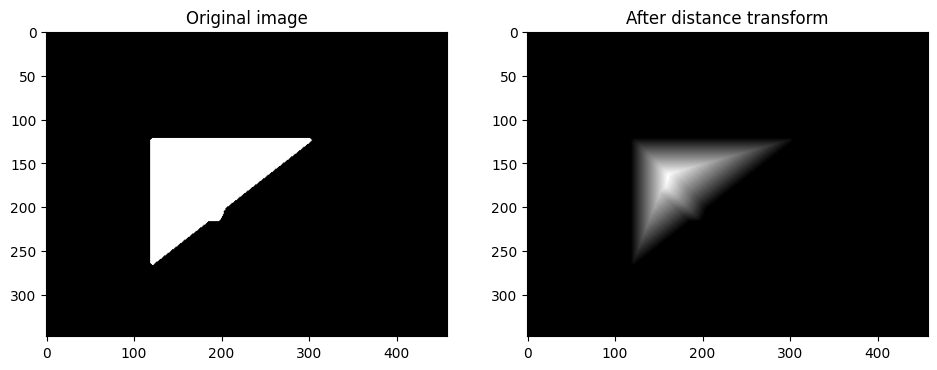

In [45]:
if __name__ == "__main__":
    im = utils.read_image("noisy-filtered.png", image_folder=pathlib.Path("image_processed")) # <-- This image is created in noise_filtering
    binary_image = (im != 0)

    plt.figure(figsize=(30, 10))

    distance = distance_transform(binary_image)

    assert im.shape == distance.shape, "Expected image shape ({}) to be same as resulting image shape ({})".format(
            im.shape, distance.shape)
    assert distance.dtype == np.int32, "Expected resulting image dtype to be np.int32. Was: {}".format(
            distance.dtype)

    distance = utils.to_uint8(distance)
    utils.save_im("noisy-distance.png", distance)

    plt.figure(figsize=(30, 10))

    plt.subplot(1, 5, 1)
    plt.imshow(im, cmap="gray")
    plt.title("Original image")

    plt.subplot(1, 5, 2)
    plt.imshow(distance, cmap="gray")
    plt.title("After distance transform")
